<a href="https://colab.research.google.com/github/tranduchoa518-lang/fake-news-detection/blob/main/notebook/07_rnn_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas numpy scikit-learn tensorflow

In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

drive.mount('/content/drive')

np.random.seed(42)
tf.random.set_seed(42)

Mounted at /content/drive


In [3]:
DATA_DIR = "/content/drive/MyDrive/fake-news-detection/data/processed"

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

for df in [train_df, val_df, test_df]:
    df["text"] = df["text"].fillna("").astype(str)
    df["label"] = df["label"].astype(int)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (50493, 2)
Validation: (10820, 2)
Test: (10821, 2)


In [4]:
MAX_WORDS = 30000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(train_df["text"])

X_train = pad_sequences(
    tokenizer.texts_to_sequences(train_df["text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    tokenizer.texts_to_sequences(val_df["text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    tokenizer.texts_to_sequences(test_df["text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

In [5]:
model = Sequential([
    Embedding(vocab_size, 128, input_length=MAX_LEN),

    LSTM(64),

    Dense(64, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 182s 227ms/step - accuracy: 0.7203 - loss: 0.5349 - val_accuracy: 0.5992 - val_loss: 0.6428
Epoch 2/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 181s 229ms/step - accuracy: 0.7955 - loss: 0.4487 - val_accuracy: 0.8470 - val_loss: 0.3684
Epoch 3/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 202s 230ms/step - accuracy: 0.8216 - loss: 0.4120 - val_accuracy: 0.9111 - val_loss: 0.2555
Epoch 4/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 181s 230ms/step - accuracy: 0.9552 - loss: 0.1342 - val_accuracy: 0.9675 - val_loss: 0.0944
Epoch 5/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 202s 230ms/step - accuracy: 0.9854 - loss: 0.0483 - val_accuracy: 0.9718 - val_loss: 0.0889


In [7]:
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

results = {
    "Model": "RNN-LSTM",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0)
}

print(pd.DataFrame([results]))
print(classification_report(y_test, y_pred))

339/339 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step
      Model  Accuracy  Precision    Recall  F1-score
0  RNN-LSTM  0.972738   0.976324  0.970535  0.973421
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      5255
           1       0.98      0.97      0.97      5566

    accuracy                           0.97     10821
   macro avg       0.97      0.97      0.97     10821
weighted avg       0.97      0.97      0.97     10821



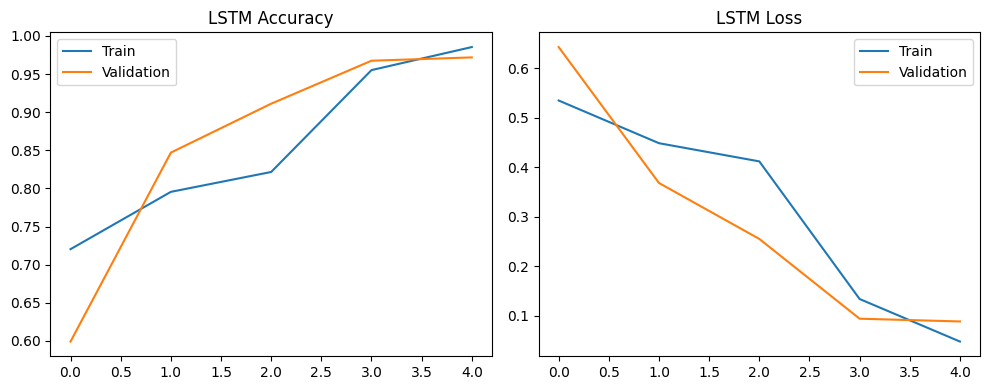

Đã lưu mô hình RNN/LSTM!


In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("LSTM Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("LSTM Loss")
plt.legend()

plt.tight_layout()
plt.show()

os.makedirs("results", exist_ok=True)

model.save("results/rnn_lstm_model.keras")

with open("results/rnn_metrics.json", "w") as f:
    json.dump(results, f, indent=4)

print("Đã lưu mô hình RNN/LSTM!")